In [1]:
!pip install avalanche-lib

In [22]:
from avalanche.benchmarks.classic import SplitMNIST
from avalanche.evaluation.metrics import forgetting_metrics, accuracy_metrics,\
    loss_metrics, timing_metrics, cpu_usage_metrics, StreamConfusionMatrix,\
    disk_usage_metrics, gpu_usage_metrics, \
    bwt_metrics, forward_transfer_metrics
from avalanche.models import SimpleMLP
from avalanche.logging import InteractiveLogger, TextLogger, TensorboardLogger
from avalanche.training.plugins import EvaluationPlugin
from avalanche.training import Naive

from torch.optim import SGD
from torch.nn import CrossEntropyLoss

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
benchmark = SplitMNIST(n_experiences=5)
model = SimpleMLP(num_classes=benchmark.n_classes)

tb_logger =  TensorboardLogger(tb_log_dir="./tb_logs")
text_logger = TextLogger(open("log.txt", "a"))
interactive_logger = InteractiveLogger()

eval_plugin = EvaluationPlugin(
    accuracy_metrics(minibatch=True, epoch=True, experience=True, stream=True),
    bwt_metrics(experience=True, stream=True),
    forward_transfer_metrics(experience=True, stream=True),
    loss_metrics(minibatch=True, epoch=True, experience=True, stream=True),
    timing_metrics(epoch=True),
    cpu_usage_metrics(experience=True),
    forgetting_metrics(experience=True, stream=True),
    StreamConfusionMatrix(num_classes=benchmark.n_classes, save_image=False),
    disk_usage_metrics(minibatch=True, epoch=True, experience=True, stream=True),
    loggers=[interactive_logger, text_logger, tb_logger]
)

cl_strategy = Naive(
    model,
    SGD(model.parameters(), lr=0.001, momentum=0.9),
    CrossEntropyLoss(),
    train_mb_size=500,
    train_epochs=1,
    eval_mb_size=100,
    evaluator=eval_plugin,
    eval_every=0
)

/opt/conda/lib/python3.10/site-packages/avalanche/training/templates/base.py:468: PositionalArgumentsDeprecatedWarning: Avalanche is transitioning to strategy constructors that accept named (keyword) arguments only. This is done to ensure that there is no confusion regarding the meaning of each argument (strategies can have many arguments). Your are passing 3 positional arguments to the Naive.__init__ method. Consider passing them as names arguments. The ability to pass positional arguments will be removed in the future.
  warnings.warn(error_str, category=PositionalArgumentsDeprecatedWarning)


In [4]:
results = []

print("Initial evaluation")
cl_strategy.eval(benchmark.test_stream)

for experience in benchmark.train_stream:
    print("Start of experience:", experience.current_experience)
    print("Current Classes:", experience.classes_in_this_experience)

    cl_strategy.train(experience, eval_streams=[benchmark.test_stream])

    print("Training completed")
    res = cl_strategy.eval(benchmark.test_stream)
    results.append(res)

Initial evaluation
-- >> Start of eval phase << --
-- Starting eval on experience 0 (Task 0) from test stream --
100%|██████████| 21/21 [00:00<00:00, 39.13it/s]
> Eval on experience 0 (Task 0) from test stream ended.
	CPUUsage_Exp/eval_phase/test_stream/Task000/Exp000 = 155.7785
	DiskUsage_Exp/eval_phase/test_stream/Task000/Exp000 = 509.0547
	Loss_Exp/eval_phase/test_stream/Task000/Exp000 = 2.3789
	Top1_Acc_Exp/eval_phase/test_stream/Task000/Exp000 = 0.0974
-- Starting eval on experience 1 (Task 0) from test stream --
100%|██████████| 22/22 [00:00<00:00, 35.72it/s]
> Eval on experience 1 (Task 0) from test stream ended.
	CPUUsage_Exp/eval_phase/test_stream/Task000/Exp001 = 148.6946
	DiskUsage_Exp/eval_phase/test_stream/Task000/Exp001 = 509.3877
	Loss_Exp/eval_phase/test_stream/Task000/Exp001 = 2.2725
	Top1_Acc_Exp/eval_phase/test_stream/Task000/Exp001 = 0.2593
-- Starting eval on experience 2 (Task 0) from test stream --
100%|██████████| 20/20 [00:00<00:00, 37.21it/s]
> Eval on experie

In [5]:
for experience in benchmark.train_stream:
    print("Start of experience:", experience.current_experience)
    print("Current Classes:", experience.classes_in_this_experience)

Start of experience: 0
Current Classes: [8, 7]
Start of experience: 1
Current Classes: [1, 4]
Start of experience: 2
Current Classes: [3, 6]
Start of experience: 3
Current Classes: [9, 2]
Start of experience: 4
Current Classes: [0, 5]


In [11]:
def extract_metrics(res, exp_id):
    row = {"experience": exp_id}

    for k, v in res.items():
        # Accuracy
        if "Top1_Acc_Exp/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]   # Exp000, Exp001, ...
            row[f"test_acc_{exp_name}"] = v
        elif "Top1_Acc_Stream/eval_phase/test_stream" in k:
            row["test_acc_stream"] = v

        # Loss
        if "Loss_Exp/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]
            row[f"test_loss_{exp_name}"] = v
        elif "Loss_Stream/eval_phase/test_stream" in k:
            row["test_loss_stream"] = v

        # Timing
        elif "Time_Epoch/train_phase/train_stream" in k:
            row["train_time_epoch"] = v

        # CPU
        elif "CPUUsage_Exp/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]
            row[f"cpu_usage_{exp_name}"] = v

        # Disk
        if "DiskUsage_Exp/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]
            row[f"test_disk_{exp_name}"] = v
        elif "DiskUsage_Stream/eval_phase/test_stream" in k:
            row["test_disk_stream"] = v

        # Continual learning metrics
        elif "StreamBWT/eval_phase/test_stream" in k:
            row["BWT_stream"] = v
        elif "ExperienceBWT/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]
            row[f"BWT_{exp_name}"] = v
        elif "StreamForwardTransfer/eval_phase/test_stream" in k:
            row["FWT_stream"] = v
        elif "ExperienceForwardTransfer/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]
            row[f"FWT_{exp_name}"] = v
        elif "StreamForgetting/eval_phase/test_stream" in k:
            row["Forgetting_stream"] = v
        elif "ExperienceForgetting/eval_phase/test_stream" in k:
            exp_name = k.split("/")[-1]
            row[f"Forgetting_{exp_name}"] = v

        # Confusion matrix
        elif "ConfusionMatrix_Stream/eval_phase/test_stream" in k:
            row["confusion_matrix"] = v

    return row

clean_results = [extract_metrics(res, i) for i, res in enumerate(results)]
results_df = pd.DataFrame(clean_results)
display(results_df)

,experience,test_acc_Exp000,test_loss_Exp000,cpu_usage_Exp000,test_disk_Exp000,test_acc_Exp001,test_loss_Exp001,cpu_usage_Exp001,test_disk_Exp001,test_acc_Exp002,...,Forgetting_Exp000,FWT_Exp002,BWT_Exp001,Forgetting_Exp001,FWT_Exp003,BWT_Exp002,Forgetting_Exp002,FWT_Exp004,BWT_Exp003,Forgetting_Exp003
0,0,0.961039,0.265311,150.555618,547.062500,0.000000,4.476054,153.274754,547.403320,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.000000,2.817160,152.680855,586.032227,0.981578,0.193696,142.609908,586.553711,0.000000,...,0.961039,-0.060976,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0.069930,2.814410,150.594536,624.784180,0.339632,1.555664,155.779711,625.305664,0.979675,...,0.891109,-0.060976,-0.641946,0.641946,-0.093582,NaN,NaN,NaN,NaN,NaN
3,3,0.009491,2.662951,150.402582,664.300781,0.299953,1.962795,153.671933,664.822266,0.242378,...,0.951548,-0.060976,-0.681625,0.681625,-0.093582,-0.737297,0.737297,-0.138355,NaN,NaN
4,4,0.001998,2.724324,151.038245,712.076172,0.315068,2.082812,153.507864,712.597656,0.001524,...,0.959041,-0.060976,-0.666509,0.666509,-0.093582,-0.978150,0.978150,-0.138355,-0.190103,0.190103


In [14]:
print(list(results_df.columns))

['experience', 'test_acc_Exp000', 'test_loss_Exp000', 'cpu_usage_Exp000', 'test_disk_Exp000', 'test_acc_Exp001', 'test_loss_Exp001', 'cpu_usage_Exp001', 'test_disk_Exp001', 'test_acc_Exp002', 'test_loss_Exp002', 'cpu_usage_Exp002', 'test_disk_Exp002', 'test_acc_Exp003', 'test_loss_Exp003', 'cpu_usage_Exp003', 'test_disk_Exp003', 'test_acc_Exp004', 'test_loss_Exp004', 'cpu_usage_Exp004', 'test_disk_Exp004', 'test_acc_stream', 'BWT_stream', 'FWT_stream', 'test_loss_stream', 'Forgetting_stream', 'confusion_matrix', 'test_disk_stream', 'train_time_epoch', 'FWT_Exp001', 'BWT_Exp000', 'Forgetting_Exp000', 'FWT_Exp002', 'BWT_Exp001', 'Forgetting_Exp001', 'FWT_Exp003', 'BWT_Exp002', 'Forgetting_Exp002', 'FWT_Exp004', 'BWT_Exp003', 'Forgetting_Exp003']



================ TEST_ACC_EXP MATRIX ================



,experience,test_acc_Exp000,test_acc_Exp001,test_acc_Exp002,test_acc_Exp003,test_acc_Exp004
0,0,0.961039,0.000000,0.000000,0.000000,0.000000
1,1,0.000000,0.981578,0.000000,0.000000,0.000000
2,2,0.069930,0.339632,0.979675,0.000000,0.000000
3,3,0.009491,0.299953,0.242378,0.964723,0.000000
4,4,0.001998,0.315068,0.001524,0.774620,0.698184



================ TEST_LOSS_EXP MATRIX ================



,experience,test_loss_Exp000,test_loss_Exp001,test_loss_Exp002,test_loss_Exp003,test_loss_Exp004
0,0,0.265311,4.476054,4.991049,4.977893,4.812855
1,1,2.817160,0.193696,4.967283,5.216825,4.860204
2,2,2.814410,1.555664,0.352759,4.244982,4.280970
3,3,2.662951,1.962795,1.433045,0.801778,3.539702
4,4,2.724324,2.082812,2.277290,1.225317,0.970079



================ CPU_USAGE_EXP MATRIX ================



...

,experience,test_acc_stream,BWT_stream,FWT_stream,test_loss_stream,Forgetting_stream,test_disk_stream
0,0,0.1924,0.000000,-0.259329,3.899888,0.000000,548.524414
1,1,0.2078,-0.961039,-0.160152,3.557146,0.961039,587.674805
2,2,0.2787,-0.766528,-0.137962,2.630000,0.766528,626.607422
3,3,0.3100,-0.790157,-0.138060,2.056945,0.790157,674.206055
4,4,0.3562,-0.698451,-0.138060,1.866198,0.698451,714.162109



================ OTHER_METRICS MATRIX ================



,experience,train_time_epoch
0,0,2.471056
1,1,2.655640
2,2,2.289009
3,3,2.299350
4,4,2.214034



================ CONFUSION MATRIX ================



/var/tmp/ipykernel_36973/464042639.py:56: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cm = np.array(cm)


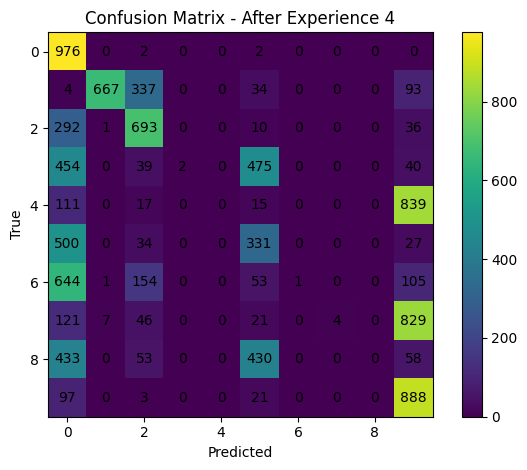

In [27]:
test_acc_exp = [c for c in results_df.columns if c.startswith("test_acc_Exp")]
test_loss_exp = [c for c in results_df.columns if c.startswith("test_loss_Exp")]
cpu_usage_exp = [c for c in results_df.columns if c.startswith("cpu_usage_Exp")]
test_disk_exp = [c for c in results_df.columns if c.startswith("test_disk_Exp")]
bwt_exp = [c for c in results_df.columns if c.startswith("BWT_Exp")]
fwt_exp = [c for c in results_df.columns if c.startswith("FWT_Exp")]
forgetting_exp = [c for c in results_df.columns if c.startswith("Forgetting_Exp")]
stream_metrics = [c for c in results_df.columns if c.endswith("_stream")]
other_metrics = ["train_time_epoch"]

metric_group_names = [
    "test_acc_exp",
    "test_loss_exp",
    "cpu_usage_exp",
    "test_disk_exp",
    "bwt_exp",
    "fwt_exp",
    "forgetting_exp",
    "stream_metrics",
    "other_metrics"
]

for each in metric_group_names:
    if each == "fwt_exp":

        print("\n================ FORWARD TRANSFER SUMMARY ================\n")
        print("Forward transfer for a task is measured only once: right before that task is trained.")
        print("So for FWT_Exp00k, the meaningful value is the first non-NaN entry in that column.\n")
        
        for col in globals()[each]:
            task_id = int(col.split("Exp")[-1])
            
            first_valid_idx = results_df[col].first_valid_index()
            
            if first_valid_idx is not None:
                val = results_df.loc[first_valid_idx, col]
        
                print(f"Task {task_id}: FWT = {val:.6f} (measured after Experience {first_valid_idx}, before training Task {task_id})")
        
                if val > 0:
                    print(f"  Interpretation: previous tasks helped the model on Task {task_id} before it was learned.\n")
                elif val < 0:
                    print(f"  Interpretation: previous tasks hurt the model on Task {task_id} before it was learned.\n")
                else:
                    print(f"  Interpretation: previous tasks had no effect on Task {task_id} before it was learned.\n")

        continue
                    
    print(f"\n================ {each.upper()} MATRIX ================\n")
    display(results_df[["experience"]+globals()[each]])

print(f"\n================ {'confusion matrix'.upper()} ================\n")
num_exp = len(results_df)

for idx, cm in list(results_df["confusion_matrix"].items())[-1:]:
    cm = np.array(cm)

    plt.figure()
    plt.imshow(cm)
    plt.title(f"Confusion Matrix - After Experience {idx}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()

    # Optional: show values inside cells (small matrices only)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, int(cm[i, j]),
                     ha="center", va="center")

    plt.tight_layout()
    plt.show()

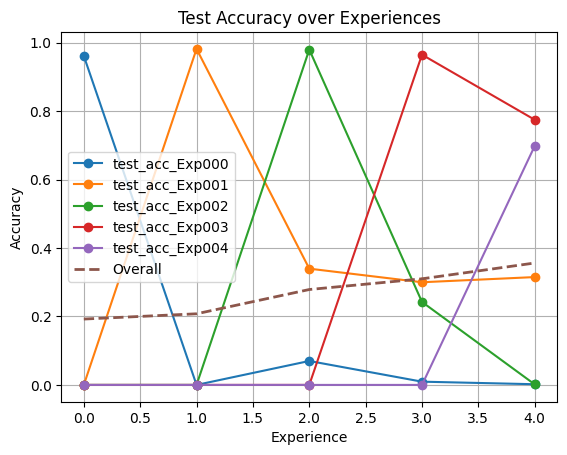

In [29]:
test_acc_df = results_df[["experience"] + globals()["test_acc_exp"]]

plt.figure()

# loop through task columns (skip 'experience')
for col in test_acc_df.columns[1:]:
    plt.plot(test_acc_df["experience"],
             test_acc_df[col],
             marker='o',
             label=col)

# optional: overall accuracy
if "test_acc_stream" in results_df.columns:
    plt.plot(results_df["experience"],
             results_df["test_acc_stream"],
             linestyle='--',
             linewidth=2,
             label="Overall")

plt.title("Test Accuracy over Experiences")
plt.xlabel("Experience")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

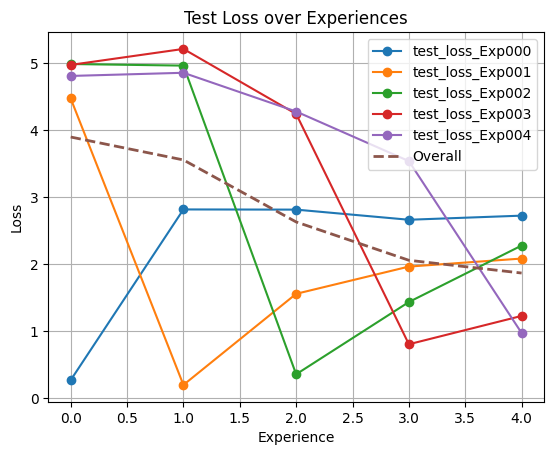

In [30]:
test_loss_df = results_df[["experience"] + globals()["test_loss_exp"]]

plt.figure()

for col in test_loss_df.columns[1:]:
    plt.plot(test_loss_df["experience"],
             test_loss_df[col],
             marker='o',
             label=col)

if "test_loss_stream" in results_df.columns:
    plt.plot(results_df["experience"],
             results_df["test_loss_stream"],
             linestyle='--',
             linewidth=2,
             label="Overall")

plt.title("Test Loss over Experiences")
plt.xlabel("Experience")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
%load_ext tensorboard
%tensorboard --logdir ./tb_logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6008 (pid 55654), started 0:01:03 ago. (Use '!kill 55654' to kill it.)